# CO1192: Machine Learning Foundations
## Individual Portfolio 4 — Capstone Project

| | |
|---|---|
| **Student Name** | Ali Haider |
| **Student ID (ULan)** | G21402240 |
| **Student ID (UCBD)** | 2601060040 |
| **Module** | CO1192: Machine Learning Foundations |
| **Tutor** | Jahid Hasan Siddiqui |
| **Deadline** | Friday, 27 July 2026, 23:59 |

---
### Portfolio 4 Notebook Structure
| Task | Description |
|---|---|
| Task 1 | Problem Definition, Data Preprocessing & Baseline Model |
| Task 2 | Cross-Validation and Hyperparameter Tuning |
| Task 3 | Feature Reduction via PCA |
| Task 4 | Model Comparison and Reflection |

---
## Project Setup: Importing Libraries

- `numpy`, `pandas` — numerical computation and data manipulation
- `matplotlib`, `seaborn` — data visualisation
- `sklearn.impute` — `SimpleImputer` fills missing values using median for continuous numeric columns and mode (most_frequent) for categorical columns (fitted on training set only).
- `sklearn.preprocessing` — `StandardScaler` standardises features to mean = 0 and std = 1, as required by Logistic Regression for stable optimisation and by PCA for correct component extraction. `LabelEncoder` encodes binary categorical features (fitted on training data only).
- `sklearn.linear_model` — `LogisticRegression` the algorithm used to train the 3 models - baseline, tuned and tuned + PCA. This model is selected because it is a binary classification algorithm, ideal for the dataset provided.
- `sklearn.pipeline` — `Pipeline` chains `StandardScaler` and `LogisticRegression` so that scaling is fitted inside each CV fold, preventing leakage into the validation fold.
- `sklearn.decomposition` — `PCA` reduces the feature space in Task 3 by identifying principal components that capture 90% of total variance.
- `sklearn.model_selection` — `train_test_split` splits data 80/20 before any preprocessing, `cross_val_score` and `KFold` used in Task 2 to perform 5-fold cross-validation on the baseline model and `GridSearchCV` used in Task 2 to search hyperparameter combinations to find the optimal one.
- `sklearn.metrics` — `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`, `ConfusionMatrixDisplay`, `roc_curve`, `auc`, `RocCurveDisplay`, `classification_report` - All standard classification metrics were used to provide a complete evaluation: accuracy for overall performance, precision and recall for error-type control (with recall prioritised for clinical safety), F1 for balanced comparison, confusion matrix and classification report for error diagnostics, and ROC-AUC for discrimination ability to ensure a meaningful model comparison.
- `joblib` — saves and reloads the best trained model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, RocCurveDisplay, classification_report
)

sns.set(style='whitegrid', context='notebook')
np.random.seed(42)
pd.set_option('display.max_columns', None)

print('Libraries imported successfully.')

Libraries imported successfully.


---
---
# Task 1: Problem Definition, Data Preprocessing and Baseline Model

## 1.1 Problem Definition

**Problem:** Heart disease is the leading cause of mortality worldwide. Early identification of patients at risk enables clinical intervention before any irreversible damage occurs. The UCI Heart Disease dataset provides anonymised clinical measurements from patients across multiple institutions, making it appropriate for building a predictive binary risk screening model, where based on a patient's clinical measurements, a prediction can be made on whether a patient has heart disease or not, making it helpful for early screening as a supporting tool for making treatment decisions.

**Machine Learning Task and Algorithm Selection:** The machine learning task for this dataset and the problem is `Binary Classification` as the target variable `num` representing the severity of the heart disease (0 – 4) needs to be binarised to predict whether a patient has heart disease or not (values 1, 2, 3, and 4 binarised to 1 indicating disease is present and value 0 remains 0 indicating no disease is present). As a result, the appropriate algorithm that should be used for this machine learning task is `Logistic Regression` due to the following reasons:





| Reason | Detail |
|---|---|
| Binary output | Designed for binary classification where outputs are only 0 and 1 |
| Interpretable | Logistic Regression coefficients indicate the direction of   each feature's effect on the probability of heart disease as well as the strength or magnitude of that effect. This means that these coefficients can be used by medical doctors to calculate how altering clinical measurements could impact disease risk. |

**Primary Evaluation Metric: F1-Score**
F1-Score is chosen as the main evaluation metric for the baseline, tuned and tuned + PCA models because it considers both precision and recall, which makes sure that the detection of false positives (no heart disease present but predicted) and false negatives (heart disease present but not detected) receives the same focus. Accuracy wasn't used because in this dataset 44% patients have no disease and 56% patients have heart disease so a model could still get 56% accuracy on the majority group while still failing to make correct predictions for the minority group, making a lot of actually sick patients go unnoticed. Incase of precision and recall alone, precision ignores false negatives (missed heart disease patients), while recall alone ignores false positives (healthy patients wrongly flagged as heart disease patients), making their individual usage for model evaluation not viable. As F1-Score captures both error types, it makes it the most appropriate metric for comparison between the three models.

## 1.2 Loading the Dataset

In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Please update this path to the location of heart_disease_uci.csv in your Google Drive
data_path = '/content/drive/My Drive/heart_disease_uci.csv'
df_raw = pd.read_csv(data_path)

print(f'Dataset loaded: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns')
print()
df_raw.head()

Mounted at /content/drive
Dataset loaded: 920 rows x 16 columns



,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## 1.3 Data Type Verification and Conversion

In [3]:
df = df_raw.copy()

print('Column dtypes before conversion:')
print(df.dtypes)
print()

Column dtypes before conversion:
id            int64
age           int64
sex          object
dataset      object
cp           object
trestbps    float64
chol        float64
fbs          object
restecg      object
thalch      float64
exang        object
oldpeak     float64
slope        object
ca          float64
thal         object
num           int64
dtype: object



**Observation:** All numeric columns are confirmed to be of correct data type and does not require any data type conversion.

**Justification:** Ensuring correct data types before any further processing prevents errors in imputation, encoding, and scaling because a single assigned column can cause entire preprocessing steps to fail.

## 1.4 Exploratory Data Analysis (EDA)

### 1.4.1 Dataset Overview and Missing Values

In [4]:
print('Shape:', df.shape)
print()
print('Statistical Summary:')
display(df.describe())
print()
print('Missing Values:')
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Count': missing, 'Percentage (%)': missing_pct})
print(missing_df[missing_df['Count'] > 0])

Shape: (920, 16)

Statistical Summary:


,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000



Missing Values:
          Count  Percentage (%)
trestbps     59            6.41
chol         30            3.26
fbs          90            9.78
restecg       2            0.22
thalch       55            5.98
exang        55            5.98
oldpeak      62            6.74
slope       309           33.59
ca          611           66.41
thal        486           52.83


**Observation:** The statistical summary reveals the distribution of the target and feature variables, where columns with missingness may indicate that the missingness itself is a meaningful signal rather than random absence.

**Justification:** Examining missing value percentages before imputation is essential to choose the correct strategy. Columns with very missingness may need to be treated by creating a binary 'was_missing' indicator column rather than simple imputation, as the absence of the measurement may correlate with disease severity itself.

### 1.4.2 Missing Value Pattern Analysis

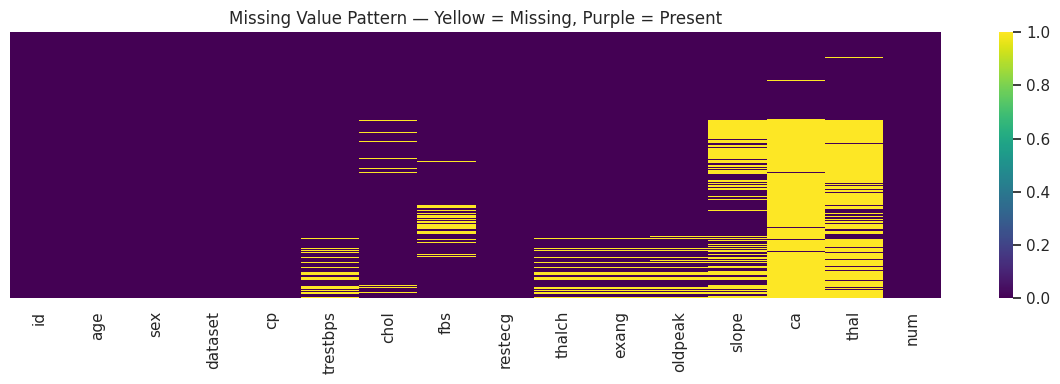

Columns with missing values:
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
dtype: int64

Columns with >30% missing values (candidates for missing indicator):
slope    33.59
ca       66.41
thal     52.83
dtype: float64


In [5]:
# Visualising which columns have missing values

# Heatmap of missing values
plt.figure(figsize=(12, 4))
sns.heatmap(df.isnull(), yticklabels=False, cbar=True, cmap='viridis')
plt.title('Missing Value Pattern — Yellow = Missing, Purple = Present')
plt.tight_layout()
plt.show()

# Columns with missing values
print('Columns with missing values:')
missing_cols = []
for c in df.columns:
    if df[c].isnull().any():
        missing_cols.append(c)
print(df[missing_cols].isnull().sum())
print()

# Flag for High missingness columns (>30%) and Low missingness columns
high_missing = missing_pct[missing_pct > 30]
if len(high_missing) > 0:
    print('Columns with >30% missing values (candidates for missing indicator):')
    print(high_missing)
else:
    print('No columns exceed 30% missing — standard imputation is appropriate.')

**Observation:** The missing value heatmap reveals whether missing values are randomly distributed or concentrated in specific locations, which may indicate that certain patients did not undergo specific tests, which itself may correlate with disease prediction. In this case, it can be seen that for `slope`, `ca` and `thal`, the missing values are highly concentrated in one location, indicating that certain hospitals did not contain data for these three specific variables, indicating potentially wrong hospital practices which could have affected the final diagnosis of the patients if these data were not considered while making the decisions.

**Justification:** Identifying high-missingness columns before imputation prevents loss of predictive signal as the missingness pattern may itself be a meaningful signal for disease prediction. So these columns will receive a binary 'was_missing' indicator in addition to standard imputation, as Logistic Regression cannot handle NaN values.

### 1.4.3 Target Variable Distribution

Target variable (num) distribution:
num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64



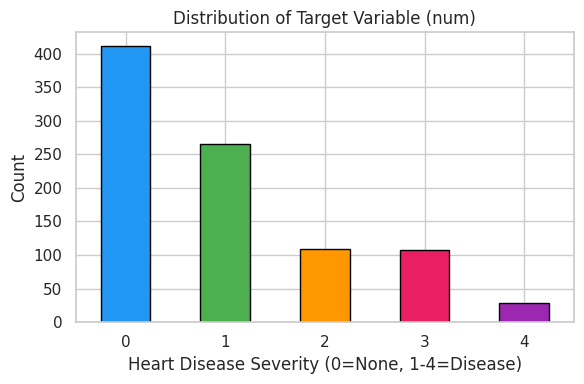

In [6]:
print('Target variable (num) distribution:')
print(df['num'].value_counts().sort_index())
print()

plt.figure(figsize=(6, 4))
df['num'].value_counts().sort_index().plot(
    kind='bar',
    color=['#2196F3','#4CAF50','#FF9800','#E91E63','#9C27B0'],
    edgecolor='black'
)
plt.title('Distribution of Target Variable (num)')
plt.xlabel('Heart Disease Severity (0=None, 1-4=Disease)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observation:** The majority of patients have no heart disease (num=0) or mild disease (num=1). After binarising, the dataset will have a reasonably balanced distribution (56% no disease and 44% heart disease), requiring no special handling for distribution imbalances.

**Justification:** Confirming the distribution before binarisation ensures that the binarisation of 1–4 into a single group is justified. This is because if the disease distributions (1–4) collectively represented very few number of patients, special handling for distribution imbalances would have been required.

### 1.4.4 Outlier Analysis

Outlier Analysis (IQR method):
  age         : Q1=47.0, Q3=60.0, IQR=13.0, bounds=[27.5, 79.5], outliers=0
  trestbps    : Q1=120.0, Q3=140.0, IQR=20.0, bounds=[90.0, 170.0], outliers=28
  chol        : Q1=175.0, Q3=268.0, IQR=93.0, bounds=[35.5, 407.5], outliers=183
  thalch      : Q1=120.0, Q3=157.0, IQR=37.0, bounds=[64.5, 212.5], outliers=2
  oldpeak     : Q1=0.0, Q3=1.5, IQR=1.5, bounds=[-2.2, 3.8], outliers=16


/tmp/ipykernel_5507/95355505.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


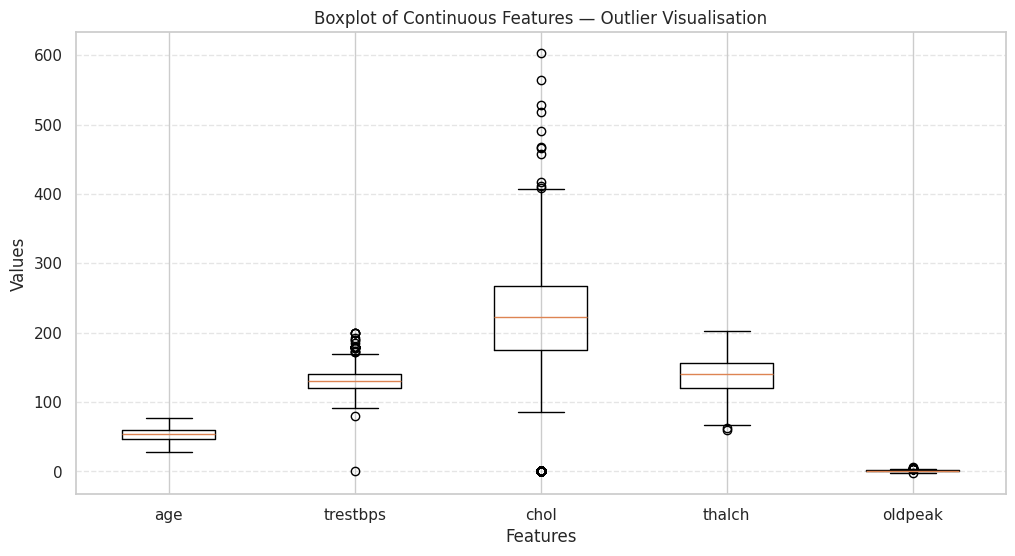

In [7]:
# IQR-based outlier analysis on continuous feature variables
numeric_cols_eda = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
numeric_cols_eda = [c for c in numeric_cols_eda if c in df.columns]

print('Outlier Analysis (IQR method):')
for col in numeric_cols_eda:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'  {col:<12}: Q1={Q1:.1f}, Q3={Q3:.1f}, IQR={IQR:.1f}, '
          f'bounds=[{lower:.1f}, {upper:.1f}], outliers={n_out}')

# Boxplot visualisation
plt.figure(figsize=(12, 6))
plt.boxplot(
    [df[col].dropna() for col in numeric_cols_eda],
    labels=numeric_cols_eda
)
plt.title('Boxplot of Continuous Features — Outlier Visualisation')
plt.xlabel('Features')
plt.ylabel('Values')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

**Observation:** The boxplot reveals the spread of each continuous feature variables and flags extreme values. Here, cholesterol (`chol`) and resting blood pressure (`trestbps`) are the ones showing most outliers but they are known to have clinically possible extreme values. For this reason, extreme values will not be removed but median imputation will be used for missing values, as the median is robust to outliers unlike the mean.

**Justification:** Outlier analysis before imputation helps guide the choice of imputation decisions and strategy as columns with extreme but clinically valid values require median imputation (robust to outliers) rather than mean imputation, which would be distorted by extreme values or outliers.

### 1.4.5 Feature vs Target Variable Correlation Analysis

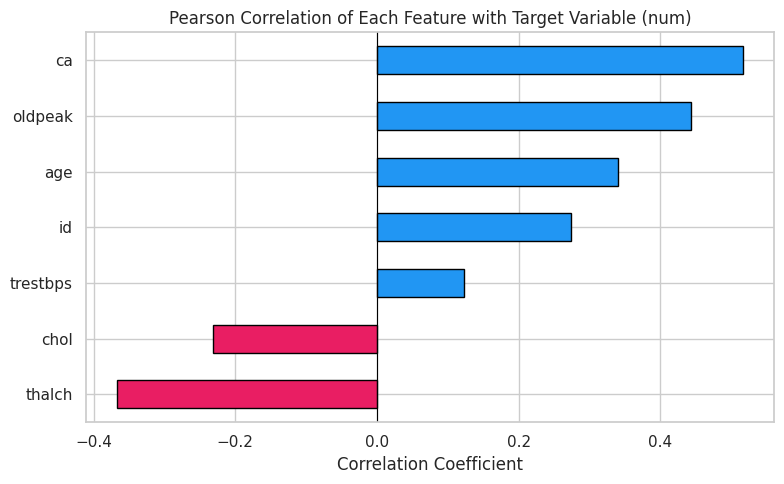

Feature correlations with target variable (sorted):
thalch     -0.3663
chol       -0.2315
trestbps    0.1223
id          0.2736
age         0.3396
oldpeak     0.4431
ca          0.5162
Name: num, dtype: float64


In [8]:
# Correlation of all features with the target variable
df_numeric_temp = df.select_dtypes(include=[np.number]).copy()
corr_with_target = df_numeric_temp.corr()['num'].drop('num').sort_values()

plt.figure(figsize=(8, 5))
colours = ['#E91E63' if x < 0 else '#2196F3' for x in corr_with_target.values]
corr_with_target.plot(kind='barh', color=colours, edgecolor='black')

plt.title('Pearson Correlation of Each Feature with Target Variable (num)')
plt.xlabel('Correlation Coefficient')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print('Feature correlations with target variable (sorted):')
print(corr_with_target.round(4))

**Observation:** The strongest predictor with a positive relationship with `num`, which is also the single most srongest predictor is `ca`, indicating that the more `ca` increases, the greater chance of heart disease. The strongest predictor with a negative relationship with `num` is `thalch or  maximum heart rate` indicating the lower the maximum heart rate is, the lesser chance of having a heart disease. Other highly correlated features which are positive correlations include `oldpeak` and `age`.

**Justification:** By the help of identifying the feature and target variable correlations, the features which carry genuine predictive signal can be identified as strongly correlated features are expected to receive large coefficients in the trained Logistic Regression model.

## 1.5 Binarising the Target Variable

In [9]:
# Binarising: 0 = no disease, 1 = disease present (any of 1,2,3,4)
df['num'] = (df['num'] > 0).astype(int)

print('Target after binarisation:')
print(df['num'].value_counts())
print()
print(f"No disease (0): {(df['num']==0).sum()} ({(df['num']==0).mean()*100:.1f}%)")
print(f"Disease    (1): {(df['num']==1).sum()} ({(df['num']==1).mean()*100:.1f}%)")

Target after binarisation:
num
1    509
0    411
Name: count, dtype: int64

No disease (0): 411 (44.7%)
Disease    (1): 509 (55.3%)


**Justification:** The original `num` column contains disease severity values 0–4, which for binary classification need to be collapsed into a two parts (heart disease: 1 - disease or 0 - no disease), which is why the values 1-4 have been binarised.

**Observation:** After binarising, the distribution is reasonably well balanced with a split of 55.3% disease and 44.7% no disease, requiring no additional work which would be needed for a very imbalanced distribution.


## 1.6 Dropping Non-Predictive Columns

In [10]:
if 'id' in df.columns:
    df.drop(columns=['id'], inplace=True)
    print('id column dropped.')
else:
    print('No id column found.')

if 'dataset' in df.columns:
    df.drop(columns=['dataset'], inplace=True)
    print('dataset column dropped.')
else:
    print('No dataset column found.')

print(f'Shape: {df.shape}')
print('Remaining columns:', df.columns.tolist())

id column dropped.
dataset column dropped.
Shape: (920, 14)
Remaining columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']



**Justification:** The `id` is a unique patient identifier. It carries no predictive signal for heart disease and `dataset` is a identifier for which region's hospital the data came from, which contains no clinical data itself to signal for a possibility of heart disease or not. Even though, it can be argued that specific region's hospitals follow certain practices so it could have the potential for prediction but as the other core clinical data already indicate the total practices combined, the `dataset` column is not required.

## 1.7 Defining X and y and Splitting the Dataset

In [11]:
y = df['num'].copy().reset_index(drop=True)
X = df.drop(columns=['num']).reset_index(drop=True)

print(f'Feature matrix (X): {X.shape}')
print(f'Target vector  (y): {y.shape}')
print('Feature columns:', X.columns.tolist())
print()
print('Distribution:', y.value_counts().to_dict())

# 80/20 split with stratify to preserve distribution balance in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train = X_train.reset_index(drop=True)
X_test  = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test  = y_test.reset_index(drop=True)

print(f'\nTrain / Test Split (80/20, stratified):')
print(f'  X_train: {X_train.shape}  |  X_test: {X_test.shape}')
print(f'  Train class balance: {y_train.value_counts().to_dict()}')
print(f'  Test  class balance: {y_test.value_counts().to_dict()}')

Feature matrix (X): (920, 13)
Target vector  (y): (920,)
Feature columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Distribution: {1: 509, 0: 411}

Train / Test Split (80/20, stratified):
  X_train: (736, 13)  |  X_test: (184, 13)
  Train class balance: {1: 407, 0: 329}
  Test  class balance: {1: 102, 0: 82}


**Observation:** The training and testing split in the ratio 80:20 has been performed successfully by using stratification as it ensures that both training and test sets will contain approximately the same proportion of positive and negative cases, resulting in both the train and test to remain balanced.


**Justification:** Before transforming any data, the dataset was split into training and testing sets to prevent data leakage. Data leakage occurs when information from outside the training set influences the preprocessing step. If imputation, encoding, or scaling are applied to the entire dataset before splitting, the testing set data will leak into the training set resulting in over optimistic accuracy results but not true predictions. If any unseen data is used for prediction, the predictions will not be as accurate as it was for the testing set. This is why, the training and testing split was performed before any data transformation.

## 1.8 Creating Missing Indicators for Columns containing Missing Data

In [12]:
# Identifying columns that had missing values in the training set
missing_in_train = X_train.columns[X_train.isnull().any()].tolist()
print('Columns with missing values in training set:', missing_in_train)

# Creating binary 'was_missing' indicator for each column that had missing values
# Indicator is created from training set, then applied to test set
for col in missing_in_train:
    train_missing_pct = X_train[col].isnull().mean() * 100
    X_train[f'{col}_was_missing'] = X_train[col].isnull().astype(int)
    X_test[f'{col}_was_missing']  = X_test[col].isnull().astype(int)
    print(f'  Created {col}_was_missing (train missing: {train_missing_pct:.1f}%)')

print(f'\nX_train shape after adding indicators: {X_train.shape}')

Columns with missing values in training set: ['trestbps', 'chol', 'fbs', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
  Created trestbps_was_missing (train missing: 6.8%)
  Created chol_was_missing (train missing: 3.7%)
  Created fbs_was_missing (train missing: 9.2%)
  Created thalch_was_missing (train missing: 6.4%)
  Created exang_was_missing (train missing: 6.4%)
  Created oldpeak_was_missing (train missing: 7.1%)
  Created slope_was_missing (train missing: 32.7%)
  Created ca_was_missing (train missing: 65.9%)
  Created thal_was_missing (train missing: 51.8%)

X_train shape after adding indicators: (736, 22)



**Justification:** For columns with missing values, the absence of a measurement may itself be clinically meaningful. This could signal patients who did not undergo a specific test may have been too ill or too healthy for it. Creating a binary 'was_missing' indicator column preserves this signal before imputation replaces the NaN in the original columns with an estimated value. Furthermore, the indicators are derived only from the training set's missing pattern, where the test set receives a 1 wherever training had missing by using the same column structure with no test-set-specific information used (to prevent data leakage).

**Source for missing indicator technique :** https://scikit-learn.org/stable/modules/impute.html#marking-imputed-values

**Observation:** Binary missing indicators have been added for each column that contained missing values in the training set. These indicators allow the model to learn from the pattern of missingness rather than treating imputed values as if they were originally observed.

## 1.9 Handling Missing Values
| Column | Strategy | Justification |
|---|---|---|
| `age`, `trestbps`, `chol`, `thalch`, `oldpeak` | Median | Robust to outliers identified in section 1.4.4 |
| `ca` | Mode | Discrete count variable so most frequent value preserves integer nature |
| `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `thal` | Mode | Categorical variable so most frequent category is used to replace the missing values. |

**Note:** All imputers are fitted on X_train only and fitted to X_test.

In [13]:
# Separating continuous numeric and categorical columns for imputation
numeric_median_cols  = [c for c in ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
                        if c in X_train.columns]
categorical_imp_cols = [c for c in ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal', 'ca']
                        if c in X_train.columns]

print('Missing values in X_train before imputation:')
print(X_train[numeric_median_cols + categorical_imp_cols].isnull().sum())
print()

# Median imputation for continuous columns — fitted on training only
imputer_median = SimpleImputer(strategy='median')
X_train[numeric_median_cols] = imputer_median.fit_transform(X_train[numeric_median_cols])
X_test[numeric_median_cols]  = imputer_median.transform(X_test[numeric_median_cols])

# Mode imputation for categorical columns — fitted on training only
if categorical_imp_cols:
    imputer_mode = SimpleImputer(strategy='most_frequent')
    X_train[categorical_imp_cols] = imputer_mode.fit_transform(X_train[categorical_imp_cols])
    X_test[categorical_imp_cols]  = imputer_mode.transform(X_test[categorical_imp_cols])

print('Missing values in X_train after imputation:')
print(X_train.isnull().sum().sum(), 'total missing')
print('Missing values in X_test after imputation:')
print(X_test.isnull().sum().sum(), 'total missing')

Missing values in X_train before imputation:
age           0
trestbps     50
chol         27
thalch       47
oldpeak      52
sex           0
cp            0
fbs          68
restecg       0
exang        47
slope       241
thal        381
ca          485
dtype: int64

Missing values in X_train after imputation:
0 total missing
Missing values in X_test after imputation:
0 total missing


**Observation:** All missing values have been successfully imputed.

**Justification:** Median imputation for continuous features avoids distortion from extreme values, unlike mean and mode imputation for categorical features preserves the most common clinical category. Furthermore, imputing after the split and fitting only on the training set ensures the test set's data distribution has no influence on the imputation values. This directly prevents data leakage that would produce artificially optimistic results.

## 1.10 Encoding Categorical Variables

In [14]:
# Label Encoding for binary 'sex' column — fitted on training only
if 'sex' in X_train.columns and X_train['sex'].dtype == object:
    le = LabelEncoder()
    X_train['sex'] = le.fit_transform(X_train['sex'])
    # Applying fitted encoder to test
    X_test['sex'] = le.transform(X_test['sex'])
    print('LabelEncoder applied to sex (fitted on training only).')
else:
    print('sex is already numeric or not present.')

# One-Hot Encoding for nominal categorical features
ohe_cols = [c for c in ['cp', 'thal', 'slope','fbs', 'restecg', 'exang']
            if c in X_train.columns]

if ohe_cols:
    X_train = pd.get_dummies(X_train, columns=ohe_cols, drop_first=True)
    X_test  = pd.get_dummies(X_test,  columns=ohe_cols, drop_first=True)

    # Reindexing test to match training column structure
    # Any category absent in test set is filled with 0
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    # Converting bool to int
    for col in X_train.columns:
        if X_train[col].dtype == bool:
            X_train[col] = X_train[col].astype(int)
            X_test[col]  = X_test[col].astype(int)

    print(f'One-Hot Encoding applied to: {ohe_cols}')

print(f'\nX_train shape after encoding: {X_train.shape}')
print('Columns:', X_train.columns.tolist())

LabelEncoder applied to sex (fitted on training only).
One-Hot Encoding applied to: ['cp', 'thal', 'slope', 'fbs', 'restecg', 'exang']

X_train shape after encoding: (736, 27)
Columns: ['age', 'sex', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'trestbps_was_missing', 'chol_was_missing', 'fbs_was_missing', 'thalch_was_missing', 'exang_was_missing', 'oldpeak_was_missing', 'slope_was_missing', 'ca_was_missing', 'thal_was_missing', 'cp_atypical angina', 'cp_non-anginal', 'cp_typical angina', 'thal_normal', 'thal_reversable defect', 'slope_flat', 'slope_upsloping', 'fbs_True', 'restecg_normal', 'restecg_st-t abnormality', 'exang_True']


**Observation:** One-Hot Encoding and Label Encoding has been performed successfully.

**Justification:**
- As `sex` is binary — `LabelEncoder` is used
- As `cp`, `thal`, `slope`, `fbs`, `restecg`, `exang` contain nominal data with multiple categories — One-Hot Encoding with `drop_first=True` is used.

Test set is reindexed to match training columns exactly, handling any category absent in the test split.

## 1.11 Standardising Features with StandardScaler



In [15]:
# StandardScaler fitted on X_train only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print('StandardScaler applied (fitted on training set only).')
print(f'X_train_scaled shape: {X_train_scaled.shape}')
print(f'Mean  (training): {X_train_scaled.mean():.6f}')
print(f'Std   (training): {X_train_scaled.std():.6f}')

StandardScaler applied (fitted on training set only).
X_train_scaled shape: (736, 27)
Mean  (training): 0.000000
Std   (training): 1.000000


**Observation:** Mean = 0 and std = 1 on the training set confirms StandardScaler has been applied correctly.

**Justification:** As, Logistic Regression is sensitive to feature scale, features on larger numeric scales would dominate the lower numeric scales, resulting in unreliable results. StandardScaler transforms each feature to mean = 0 and std = 1, ensuring all features contribute proportionally to the model. Furthermore, fitting the scaler on the training set only and transforming the test set with the fitted object is again done to prevent data leakage.

## 1.12 Training the Baseline Logistic Regression Model

In [16]:
# Training the baseline Logistic Regression model
baseline_model = LogisticRegression(
    max_iter=1000,
    solver='lbfgs',
    class_weight='balanced',
    random_state=42
)
baseline_model.fit(X_train_scaled, y_train)

print('Baseline Logistic Regression model trained.')
print(f'Features used: {X_train_scaled.shape[1]}')

Baseline Logistic Regression model trained.
Features used: 27


**Justification for `class_weight='balanced'`:** Even though the dataset is reasonably well balanced, equal weight was still assigned to maintain perfect distribution as a missed diagnosis (false negative) is more dangerous than a false alarm (false positive). `class_weight='balanced'` automatically adjusts weights inversely proportional to class frequencies, ensuring the model does not develop a bias toward the majority class.

**URL:** https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

## 1.13 Evaluating the Baseline Model

In [17]:
# Predictions and probabilities
y_pred_baseline = baseline_model.predict(X_test_scaled)
y_prob_baseline = baseline_model.predict_proba(X_test_scaled)[:, 1]

# Computing all metrics
acc_baseline  = accuracy_score(y_test, y_pred_baseline)
prec_baseline = precision_score(y_test, y_pred_baseline)
rec_baseline  = recall_score(y_test, y_pred_baseline)
f1_baseline   = f1_score(y_test, y_pred_baseline)
fpr_b, tpr_b, _ = roc_curve(y_test, y_prob_baseline)
auc_baseline  = auc(fpr_b, tpr_b)

print('Baseline Logistic Regression (Test Set):')
print(f'Accuracy  : {acc_baseline:.4f}')
print(f'Precision : {prec_baseline:.4f}')
print(f'Recall    : {rec_baseline:.4f}')
print(f'F1-Score  : {f1_baseline:.4f}')
print(f'ROC-AUC   : {auc_baseline:.4f}')

print('\nClassification Report:')
print(classification_report(y_test, y_pred_baseline))

Baseline Logistic Regression (Test Set):
Accuracy  : 0.8370
Precision : 0.8462
Recall    : 0.8627
F1-Score  : 0.8544
ROC-AUC   : 0.9140

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.80      0.81        82
           1       0.85      0.86      0.85       102

    accuracy                           0.84       184
   macro avg       0.84      0.83      0.83       184
weighted avg       0.84      0.84      0.84       184



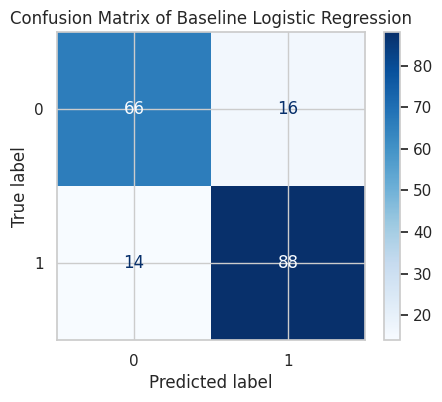

In [18]:
# Confusion Matrix
cm_baseline = confusion_matrix(y_test, y_pred_baseline)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_baseline).plot(ax=ax, cmap='Blues')
plt.title('Confusion Matrix of Baseline Logistic Regression')
plt.show()

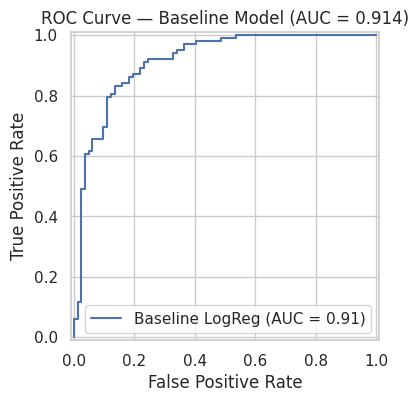

In [19]:
# ROC Curve
fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay(
    fpr=fpr_b, tpr=tpr_b, roc_auc=auc_baseline,
    estimator_name='Baseline LogReg'
).plot(ax=ax)
plt.title(f'ROC Curve — Baseline Model (AUC = {auc_baseline:.3f})')
plt.show()

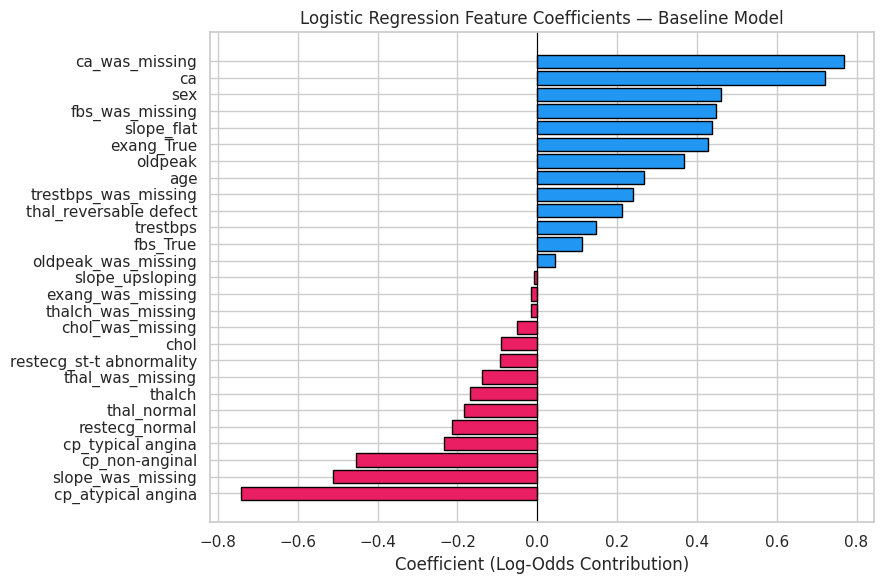

Interpretation:
  Positive (blue) → increases log-odds of heart disease
  Negative (red)  → decreases log-odds of heart disease
  Larger magnitude → stronger influence on prediction

                 Feature  Coefficient
      cp_atypical angina    -0.742964
       slope_was_missing    -0.510475
          cp_non-anginal    -0.453578
       cp_typical angina    -0.232438
          restecg_normal    -0.214518
             thal_normal    -0.183422
                  thalch    -0.169039
        thal_was_missing    -0.138552
restecg_st-t abnormality    -0.093243
                    chol    -0.090418
        chol_was_missing    -0.051584
      thalch_was_missing    -0.014754
       exang_was_missing    -0.014754
         slope_upsloping    -0.007517
     oldpeak_was_missing     0.044231
                fbs_True     0.112561
                trestbps     0.147701
  thal_reversable defect     0.213463
    trestbps_was_missing     0.240168
                     age     0.267677
                 ol

In [20]:
# Feature Coefficient Visualisation
coeff_df = pd.DataFrame({
    'Feature'     : X_train.columns,
    'Coefficient' : baseline_model.coef_[0]
}).sort_values('Coefficient')

plt.figure(figsize=(9, 6))
colors = ['#E91E63' if x < 0 else '#2196F3' for x in coeff_df['Coefficient']]
plt.barh(coeff_df['Feature'], coeff_df['Coefficient'], color=colors, edgecolor='black')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Logistic Regression Feature Coefficients — Baseline Model')
plt.xlabel('Coefficient (Log-Odds Contribution)')
plt.tight_layout()
plt.show()

print('Interpretation:')
print('  Positive (blue) → increases log-odds of heart disease')
print('  Negative (red)  → decreases log-odds of heart disease')
print('  Larger magnitude → stronger influence on prediction')
print()
print(coeff_df.to_string(index=False))

**Observation:** The baseline logistic regression model achieves strong predictive performance with an accuracy of 83.70%, an F1-score of 0.8544, and a robust ROC-AUC of 0.9140. Out of 184 test cases, the model correctly classifies 154 patients comprising 66 true negatives and 88 true positives, while keeping high-risk false negatives down to just 14. Feature coefficients reveal that `ca_was_missing` is the strongest predictor out of all, indicating that the decision for capturing signals for missing data was a correct decision. Besides, `ca` is the third strongest predictor indicating that both the presence and absence of `ca` data is a major predictor for predicitng heart disease. Furthermore, `cp_atypical angina` is the second strongest predictor with a negative relationship with `num` indicating that the decrease of `cp_atypical angina` will increase the likelihood of a positive diagnosis.



---
---
# Task 2: Cross-Validation and Hyperparameter Tuning

## 2.1 Building the Pipeline for Leakage-Free Cross-Validation

In [21]:
# Building Pipeline and ensuring StandardScaler is fitted inside each CV fold
baseline_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(
        max_iter=1000, solver='lbfgs',
        class_weight='balanced', random_state=42))
])

print('Pipeline created.')
print('Steps:', [step[0] for step in baseline_pipe.steps])

Pipeline created.
Steps: ['scaler', 'logreg']


## 2.2 5-Fold Cross-Validation on the Baseline Pipeline

In [22]:
# 5-fold cross-validation on the training set only
cv_scores_baseline = cross_val_score(
    baseline_pipe, X_train, y_train, cv=5, scoring='f1'
)

print('5-Fold CV F1 Scores (Baseline):', np.round(cv_scores_baseline, 4))
print(f'Mean CV F1 : {cv_scores_baseline.mean():.4f}')
print(f'Std  CV F1 : {cv_scores_baseline.std():.4f}')

5-Fold CV F1 Scores (Baseline): [0.8795 0.8323 0.7949 0.8098 0.825 ]
Mean CV F1 : 0.8283
Std  CV F1 : 0.0287


**Observation:** The 5 cross-validation mean F1 score is 0.8283 indicates that the model is performing reasonably well across different training and testing sets and a low standard deviation of 0.0287 confirms stable generalisation, indicating that the model is not highly sensitive to which patients it trains on.

**Justification:** Cross-validation is used because it evaluates the model's performance based on 5 distinct folds, where each fold serves as validation exactly once. This helps provide a more stable and reliable estimate on the model's performance than a single train/test split, which can produce a single performance estimate that is highly dependent on the random split and can potentially be overly optimistic or pessimistic, manifesting unreliable results. Furthermore, the std CV F1 also helps to indicate whether the model is stable or not by calculating the mean F1 variance across the 5 folds.

## 2.3 Hyperparameter Tuning with GridSearchCV

**Parameters tuned:**

| Parameter | Values | Justification |
|---|---|---|
| `logreg__C` | [0.001, 0.01, 0.1, 0.5] | Low values like 0.001, 0.01, 0.1, and 0.5 provide strong regularisation by shrinking model coefficients to prevent overfitting |
| `logreg__C` | 1.0 | Standard default value to test |
| `logreg__C` | [2.0, 5.0, 10.0] | High values like 2.0, 5.0, and 10.0 reduce regularisation strength by letting the model fit the training data more closely. |
| `logreg__penalty` | ['l2'] | L2 supported by lbfgs |
| `logreg__solver` | ['lbfgs'] | Efficient for small-medium datasets |

**Source:**
Source for parameter choice and regularisation: https://mbrenndoerfer.com/writing/ridge-regression-l2-regularization-complete-guide#google_vignette

In [23]:
# Parameter grid
param_grid = {
    'logreg__C'       : [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
    'logreg__penalty' : ['l2'],
    'logreg__solver'  : ['lbfgs']
}

# GridSearchCV with 5-fold cross-validation
grid_search = GridSearchCV(
    baseline_pipe,
    param_grid,
    cv=5,
    scoring='f1'
)
grid_search.fit(X_train, y_train)

print('Best Parameters  :', grid_search.best_params_)
print(f'Best CV F1 Score : {grid_search.best_score_:.4f}')

Best Parameters  : {'logreg__C': 0.1, 'logreg__penalty': 'l2', 'logreg__solver': 'lbfgs'}
Best CV F1 Score : 0.8416


**Observation:** The best parameter is `0.1` with a cross-validation F1 score of 0.8416, slightly higher than the baseline model CV F1 (0.8283). This indicates that the model required strong regularisation, indicating that the model may have been slightly overfitting, but not signficantly and can be considered as neglible as their F1 scores are almost identical. As, the parameter 0.1, provides the best result, it will be used for the tuned and tuned + PCA model.

Tuned Logistic Regression (C=0.1) on Test Set:
Accuracy  : 0.8478
Precision : 0.8558
Recall    : 0.8725
F1-Score  : 0.8641
ROC-AUC   : 0.9159

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.82      0.83        82
           1       0.86      0.87      0.86       102

    accuracy                           0.85       184
   macro avg       0.85      0.84      0.85       184
weighted avg       0.85      0.85      0.85       184



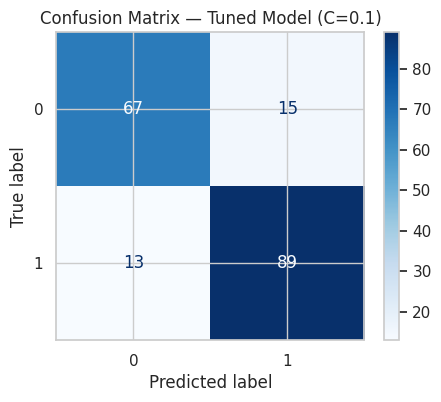

In [24]:
# Evaluating the best tuned model on the test set
tuned_model = grid_search.best_estimator_
best_C      = grid_search.best_params_['logreg__C']

y_pred_tuned = tuned_model.predict(X_test)
y_prob_tuned = tuned_model.predict_proba(X_test)[:, 1]

acc_tuned  = accuracy_score(y_test, y_pred_tuned)
prec_tuned = precision_score(y_test, y_pred_tuned)
rec_tuned  = recall_score(y_test, y_pred_tuned)
f1_tuned   = f1_score(y_test, y_pred_tuned)
fpr_t, tpr_t, _ = roc_curve(y_test, y_prob_tuned)
auc_tuned  = auc(fpr_t, tpr_t)

print(f'Tuned Logistic Regression (C={best_C}) on Test Set:')
print(f'Accuracy  : {acc_tuned:.4f}')
print(f'Precision : {prec_tuned:.4f}')
print(f'Recall    : {rec_tuned:.4f}')
print(f'F1-Score  : {f1_tuned:.4f}')
print(f'ROC-AUC   : {auc_tuned:.4f}')
print()
print('Classification Report:')
print(classification_report(y_test, y_pred_tuned))

# Confusion Matrix
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_tuned).plot(ax=ax, cmap='Blues')
plt.title(f'Confusion Matrix — Tuned Model (C={best_C})')
plt.show()

**Observation:** The tuned logistic regression model achieves strong predictive performance with an accuracy of 84.78%, an F1-score of 0.8641, and a robust ROC-AUC of 0.9159, better across all metrics than the baseline model. Out of 184 test cases, the model correctly classifies 156 patients comprising 67 true negatives and 89 true positives, while keeping high-risk false negatives down to just 13 (slightly better than the baseline model).

---
---
# Task 3: Feature Reduction via PCA

## 3.1 PCA — Scree Plot and Component Selection

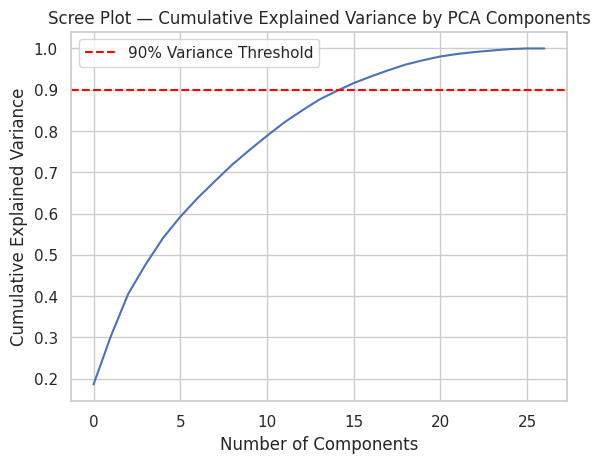

Number of components explaining 90% variance: 16
Original number of features: 27

  PC1: 0.1859 (18.59% cumulative)
  PC2: 0.1172 (30.31% cumulative)
  PC3: 0.1023 (40.54% cumulative)
  PC4: 0.0712 (47.65% cumulative)
  PC5: 0.0638 (54.03% cumulative)
  PC6: 0.0518 (59.21% cumulative)
  PC7: 0.0453 (63.74% cumulative)
  PC8: 0.0411 (67.85% cumulative)
  PC9: 0.0401 (71.86% cumulative)
  PC10: 0.0356 (75.42% cumulative)
  PC11: 0.0340 (78.82% cumulative)
  PC12: 0.0327 (82.09% cumulative)
  PC13: 0.0280 (84.90% cumulative)
  PC14: 0.0268 (87.57% cumulative)
  PC15: 0.0208 (89.65% cumulative)
  PC16: 0.0195 (91.60% cumulative)
  PC17: 0.0162 (93.22% cumulative)
  PC18: 0.0150 (94.72% cumulative)
  PC19: 0.0138 (96.10% cumulative)
  PC20: 0.0104 (97.15% cumulative)
  PC21: 0.0091 (98.06% cumulative)
  PC22: 0.0062 (98.68% cumulative)
  PC23: 0.0046 (99.14% cumulative)
  PC24: 0.0037 (99.51% cumulative)
  PC25: 0.0034 (99.85% cumulative)
  PC26: 0.0015 (100.00% cumulative)
  PC27: 0.0000 (

In [25]:
# Fitting PCA on standardised training set
pca = PCA()
pca.fit(X_train_scaled)

explained_variance  = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Scree plot
plt.figure()
plt.plot(np.cumsum(explained_variance))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Scree Plot — Cumulative Explained Variance by PCA Components')
plt.axhline(0.90, color='red', linestyle='--', label='90% Variance Threshold')
plt.legend()
plt.show()

# Number of components for 90% variance
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1

print(f'Number of components explaining 90% variance: {n_components_90}')
print(f'Original number of features: {X_train_scaled.shape[1]}')
print()
for i, var in enumerate(explained_variance):
    print(f'  PC{i+1}: {var:.4f} ({cumulative_variance[i]*100:.2f}% cumulative)')

**Observation:** From the scree chart, it can be seen that the explained variance builds up as additional components are included, where the red dashed line on the graph indicates a threshold of 90% variance accounted for. After this line, components add little new information and therefore will be removed.

**Justification:** Principal Component Analysis (PCA) was performed on the features set of the dataset so that fewer features are retained while still keeping 90% of the total explained variance. This was done to prevent overfitting by removing correlated or redundant features and to transform the correlated features into uncorrelated components, so that the model generalises better.

In [26]:
# Applying PCA with selected number of components
pca_final = PCA(n_components=n_components_90)
X_train_pca = pca_final.fit_transform(X_train_scaled)
X_test_pca  = pca_final.transform(X_test_scaled)

print(f'Original features : {X_train_scaled.shape[1]}')
print(f'Reduced features  : {X_train_pca.shape[1]}')
print(f'Variance retained : {pca_final.explained_variance_ratio_.sum()*100:.2f}%')

Original features : 27
Reduced features  : 16
Variance retained : 91.60%


PCA + Tuned Logistic Regression (16 components, C=0.1):
Accuracy  : 0.8315
Precision : 0.8447
Recall    : 0.8529
F1-Score  : 0.8488
ROC-AUC   : 0.9103

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.80      0.81        82
           1       0.84      0.85      0.85       102

    accuracy                           0.83       184
   macro avg       0.83      0.83      0.83       184
weighted avg       0.83      0.83      0.83       184



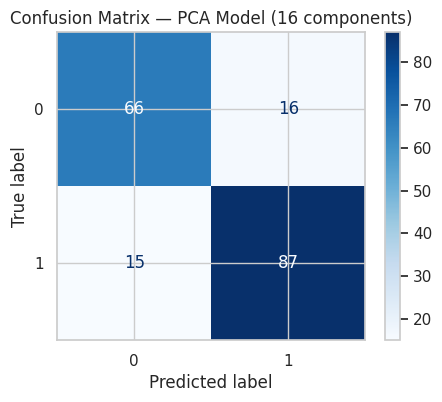

In [27]:
# Training Logistic Regression on PCA-reduced features
pca_model = LogisticRegression(
    C=best_C, max_iter=1000, solver='lbfgs',
    class_weight='balanced', random_state=42
)
pca_model.fit(X_train_pca, y_train)

y_pred_pca = pca_model.predict(X_test_pca)
y_prob_pca = pca_model.predict_proba(X_test_pca)[:, 1]

acc_pca  = accuracy_score(y_test, y_pred_pca)
prec_pca = precision_score(y_test, y_pred_pca)
rec_pca  = recall_score(y_test, y_pred_pca)
f1_pca   = f1_score(y_test, y_pred_pca)
fpr_p, tpr_p, _ = roc_curve(y_test, y_prob_pca)
auc_pca  = auc(fpr_p, tpr_p)

print(f'PCA + Tuned Logistic Regression ({n_components_90} components, C={best_C}):')
print(f'Accuracy  : {acc_pca:.4f}')
print(f'Precision : {prec_pca:.4f}')
print(f'Recall    : {rec_pca:.4f}')
print(f'F1-Score  : {f1_pca:.4f}')
print(f'ROC-AUC   : {auc_pca:.4f}')
print()
print('Classification Report:')
print(classification_report(y_test, y_pred_pca))

cm_pca = confusion_matrix(y_test, y_pred_pca)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_pca).plot(ax=ax, cmap='Blues')
plt.title(f'Confusion Matrix — PCA Model ({n_components_90} components)')
plt.show()

**Observation:** The tuned + PCA logistic regression model achieves a predictive performance of 83.15% accuracy, an F1-score of 0.8488, and a ROC-AUC of 0.9103. Out of 184 test cases, the model correctly classifies 153 patients comprising 66 true negatives and 87 true positives, while keeping high-risk false negatives down to 15. In all metrics it performs worse against the baseline and tuned model, indicating that the 10% variance removed contained actual meaningful signals for making predictions.


---
---
# Task 4: Model Comparison and Reflection

## 4.1 Full Comparison Table with CV Standard Deviations

In [28]:
cv_tuned = cross_val_score(
    tuned_model, X_train, y_train, cv=5, scoring='f1'
)

# PCA pipeline for CV
pca_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=n_components_90)),
    ('logreg', LogisticRegression(
        C=best_C, max_iter=1000, solver='lbfgs',
        class_weight='balanced', random_state=42))
])
cv_pca = cross_val_score(
    pca_pipe, X_train, y_train, cv=5, scoring='f1'
)

comparison_df = pd.DataFrame({
    'Model': [
        'Baseline (C=1.0)',
        f'Tuned (C={best_C})',
        f'PCA + Tuned ({n_components_90} components)'
    ],
    'Accuracy'        : [round(acc_baseline,4),  round(acc_tuned,4),  round(acc_pca,4)],
    'Precision'       : [round(prec_baseline,4), round(prec_tuned,4), round(prec_pca,4)],
    'Recall'          : [round(rec_baseline,4),  round(rec_tuned,4),  round(rec_pca,4)],
    'F1-Score (Test)' : [round(f1_baseline,4),   round(f1_tuned,4),   round(f1_pca,4)],
    'ROC-AUC'         : [round(auc_baseline,4),  round(auc_tuned,4),  round(auc_pca,4)],
    'Mean CV F1'      : [round(cv_scores_baseline.mean(),4), round(cv_tuned.mean(),4), round(cv_pca.mean(),4)],
    'CV F1 Std'       : [round(cv_scores_baseline.std(),4),  round(cv_tuned.std(),4),  round(cv_pca.std(),4)]
})

print('Full Model Comparison Table:')
print(comparison_df.to_string(index=False))

Full Model Comparison Table:
                      Model  Accuracy  Precision  Recall  F1-Score (Test)  ROC-AUC  Mean CV F1  CV F1 Std
           Baseline (C=1.0)    0.8370     0.8462  0.8627           0.8544   0.9140      0.8283     0.0287
              Tuned (C=0.1)    0.8478     0.8558  0.8725           0.8641   0.9159      0.8416     0.0257
PCA + Tuned (16 components)    0.8315     0.8447  0.8529           0.8488   0.9103      0.8356     0.0149


## 4.2 Visual Comparison

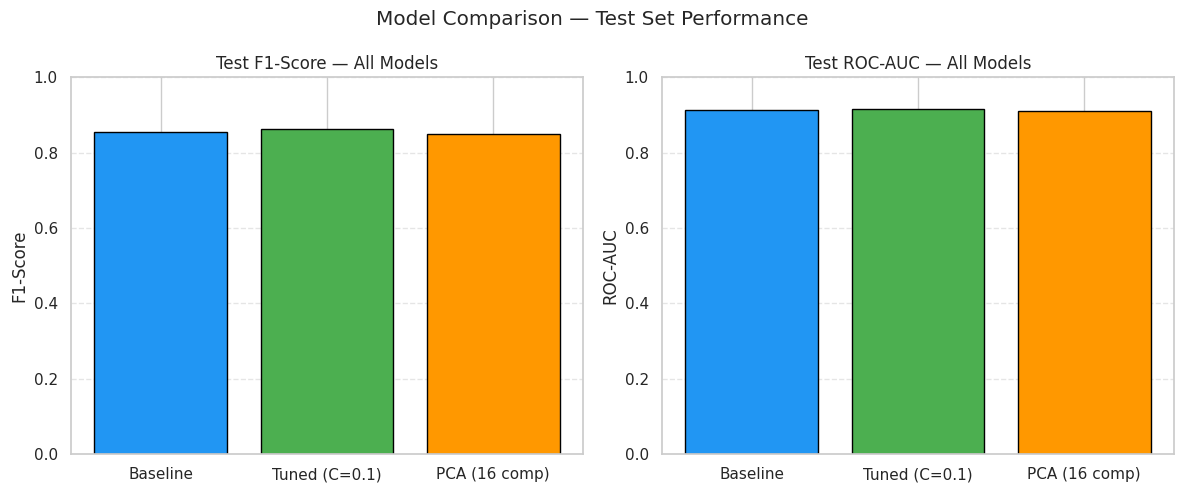

In [29]:
models_labels = [
    'Baseline',
    f'Tuned (C={best_C})',
    f'PCA ({n_components_90} comp)'
]
f1_scores  = [f1_baseline,  f1_tuned,  f1_pca]
auc_scores = [auc_baseline, auc_tuned, auc_pca]
colors = ['#2196F3', '#4CAF50', '#FF9800']

# Source: plt.subplots — https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(models_labels, f1_scores, color=colors, edgecolor='black')
axes[0].set_title('Test F1-Score — All Models')
axes[0].set_ylabel('F1-Score')
axes[0].set_ylim(0, 1)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

axes[1].bar(models_labels, auc_scores, color=colors, edgecolor='black')
axes[1].set_title('Test ROC-AUC — All Models')
axes[1].set_ylabel('ROC-AUC')
axes[1].set_ylim(0, 1)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle('Model Comparison — Test Set Performance')
plt.tight_layout()
plt.show()

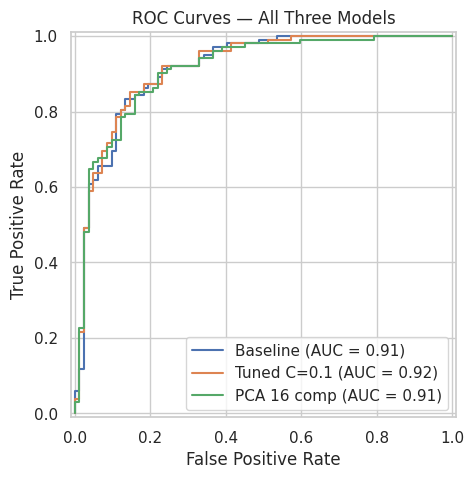

In [30]:
# ROC Curves for all three models
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay(fpr=fpr_b, tpr=tpr_b, roc_auc=auc_baseline,
                estimator_name='Baseline').plot(ax=ax)
RocCurveDisplay(fpr=fpr_t, tpr=tpr_t, roc_auc=auc_tuned,
                estimator_name=f'Tuned C={best_C}').plot(ax=ax)
RocCurveDisplay(fpr=fpr_p, tpr=tpr_p, roc_auc=auc_pca,
                estimator_name=f'PCA {n_components_90} comp').plot(ax=ax)
plt.title('ROC Curves — All Three Models')
plt.show()

**Observation:** The tuned logistic regression model with parameter 0.1 is the best performing model by achieving the highest test accuracy (84.78%), F1-score (0.8641), and ROC-AUC (0.9159) across all models, while also reducing high-risk false negatives from 14 (baseline) to 13. The baseline model is a close second with an (83.70%) accuracy, F1-score of (0.8544), ROC-AUC of (0.9140) and false negatives of 14, indicating that the default regularisation strength was already quite optimised. However, the PCA model underperforms across all metrics, indicating that the removed variance contained genuine predictive signal rather than noise.

**Overfitting Analysis:** Regarding overfitting, there is no evidence of significant overfitting in any of the three models. For baseline model, the cross-validation F1 mean (0.8283) closely aligns with its test F1 (0.8544). Incase of tuned model, the cross-validation F1 mean (0.8416) also closely aligns with its test F1 (0.8641) and for the tuned + PCA model, the cross-validation F1 mean (0.8356) also closely aligns with its test F1 (0.8488). This means that none of this model have any significant overfitting issues. Besides, the low mean cross-validation standard deviation of baseline (0.0287), tuned (0.0257) and tuned + PCA (0.0149) across the 5 CV folds also confirms consistent generalisation across all the three models.

## 4.3 Saving the Best Model

In [31]:
best_model = tuned_model
best_model_name = "Tuned"

save_path = f'best_logreg_{best_model_name.lower()}.joblib'
joblib.dump(best_model, save_path)
print(f'Best model saved: {save_path}')

# Verifying by reloading the model
loaded_model = joblib.load(save_path)
print('Model reloaded successfully.')

Best model saved: best_logreg_tuned.joblib
Model reloaded successfully.
